## This notebook conducts a numerical quantitative performance analysis of Spark, Polars, and pandas. 

*All three technologies run an ETL pipeline multiple times against data of varying volume variety (e.g., 10 million, 25 million, and 50 million rows of mock costumer transaction date).*


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

SWEEP_CSV = Path("../results/sweep_20261003-155739/sweep_summary.csv")

df = pd.read_csv(SWEEP_CSV)
df["framework"] = df["framework"].str.replace(" (local[*])", "", regex=False)

df.head(5)
#df.describe()
#df.info()

,size_m,benchmark,framework,status,median_s,rows_per_sec
0,10,Ingest,Polars,ok,4.0829,2449240
1,10,Ingest,Pandas,ok,2.9829,3352442
2,10,Ingest,Spark,ok,1.1272,8871540
3,10,Transform,Polars,ok,0.0902,110864745
4,10,Transform,Pandas,ok,1.0229,9776127


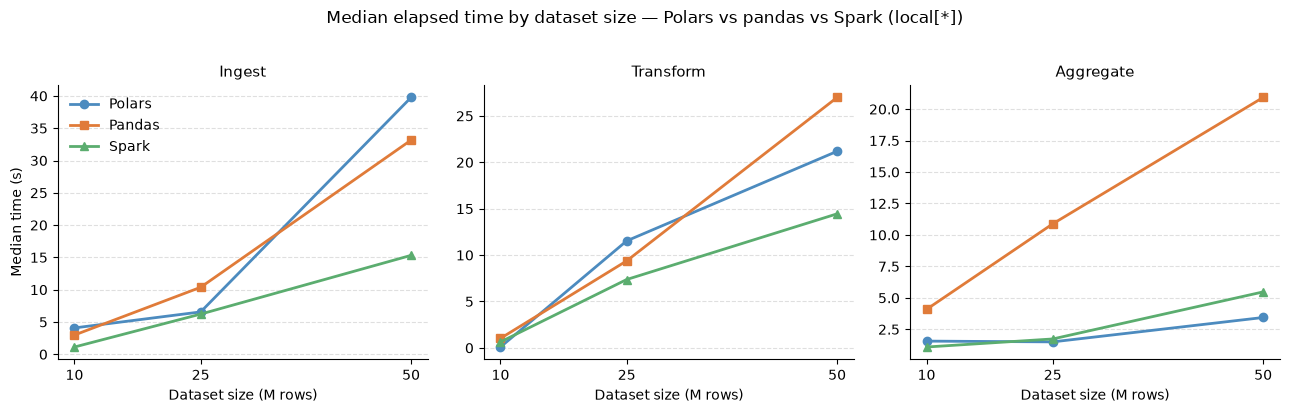

In [2]:
benchmarks = ["Ingest", "Transform", "Aggregate"]
frameworks = ["Polars", "Pandas", "Spark"]
colors     = {"Polars": "#4C8BBF", "Pandas": "#E07B39", "Spark": "#5BAD6F"}
markers    = {"Polars": "o",       "Pandas": "s",        "Spark": "^"}

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=False)
fig.suptitle(
    "Median elapsed time by dataset size — Polars vs pandas vs Spark (local[*])",
    fontsize=12, y=1.02,
)

for ax, bench in zip(axes, benchmarks):
    subset = df[df["benchmark"] == bench]
    for fw in frameworks:
        row = subset[subset["framework"] == fw].sort_values("size_m")
        ax.plot(
            row["size_m"], row["median_s"],
            label=fw, color=colors[fw], marker=markers[fw],
            linewidth=2, markersize=6,
        )
    ax.set_title(bench, fontsize=11)
    ax.set_xlabel("Dataset size (M rows)")
    ax.set_ylabel("Median time (s)" if ax is axes[0] else "")
    ax.set_xticks([10, 25, 50])
    ax.xaxis.set_minor_locator(ticker.NullLocator())
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].legend(frameon=False)
fig.tight_layout()
#plt.savefig("sweep_elapsed.png", dpi=150, bbox_inches="tight")
plt.show()